# Criterios de fotointerpretación y lectura del relieve

La fotointerpretación es el proceso de examinar las imágenes de objetos con el propósito de identificarlos y deducir su significado. Va de lo que se ve a lo que se infiere: se detectan rasgos, se reconocen e identifican, se analizan sus relaciones y se deduce el proceso o la estructura que los produjo. La calidad del resultado depende tanto de la imagen como del conocimiento del intérprete: un geomorfólogo ve en la misma foto procesos que un ingeniero forestal no ve, y viceversa {cite}`ray1960,campbell2011`.

## Metodología

El trabajo de fotointerpretación sigue un procedimiento ordenado. Primero se recopila la información existente (mapas topográficos y geológicos, informes, imágenes de distintas fechas) y se seleccionan las fotos a partir del índice de vuelo. Después se orientan los pares estereoscópicos, se delimita el área útil de cada foto para no repetir trabajo y se hace una primera lectura de conjunto, de lo general a lo particular. Luego viene la interpretación propiamente dicha: se trazan los elementos lineales (drenajes, divisorias, lineamientos, contactos) y se delimitan unidades homogéneas según los criterios que siguen. Finalmente se verifica en campo, se ajusta la interpretación y se transfiere al mapa base, corrigiendo las deformaciones de las fotos.

## Criterios de interpretación

Los elementos que usa el intérprete para reconocer los objetos se conocen como criterios o claves de interpretación {cite}`lillesand2015`.

El tono, o el color en fotos a color, es el brillo relativo de un objeto y depende de su reflectancia en la banda de la foto. Las rocas claras, como las cuarcitas o las calizas, dan tonos claros; las rocas máficas, los suelos húmedos y la vegetación densa, tonos oscuros; el agua clara es negra en el infrarrojo. La textura es la frecuencia de cambio del tono, la apariencia lisa o rugosa de una superficie, y depende de la escala: la copa de los árboles da una textura gruesa a una escala y fina a otra. La forma es el contorno de los objetos; los rasgos humanos tienden a ser geométricos y los naturales irregulares, y muchas geoformas, como los conos volcánicos, los abanicos o las cicatrices de deslizamientos, se reconocen por su forma. El tamaño, relativo a objetos conocidos, ayuda a separar rasgos parecidos de distinta escala. El patrón es la organización espacial repetida de los objetos, como el de los drenajes o el de las fracturas. Las sombras revelan la forma y la altura de los objetos y realzan el relieve, aunque también ocultan lo que está en ellas. La asociación o el contexto es la relación de un objeto con su entorno: un abanico aluvial está al pie de un frente montañoso, una terraza al lado de un río. La temporalidad, por último, es la comparación entre fotos de distintas fechas, que revela cambios como la evolución de un cauce o la reactivación de un deslizamiento.

La celda siguiente genera tres parches sintéticos con el mismo tono medio pero distinta textura y muestra cómo una medida simple, la desviación estándar local, los separa aunque el tono no lo haga. Es el principio de las medidas de textura que se usan en clasificación digital.

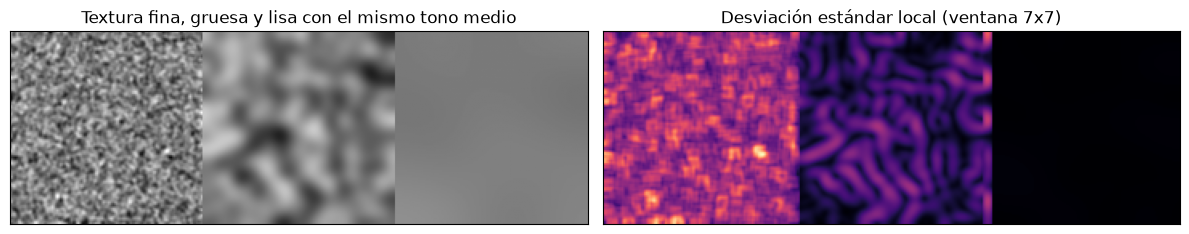

textura fina   : tono medio 0.49, desviación estándar global 0.120, local media 0.106
textura gruesa : tono medio 0.49, desviación estándar global 0.120, local media 0.043
textura lisa   : tono medio 0.49, desviación estándar global 0.020, local media 0.002


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(1)

n = 120
fino = ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 1)
grueso = ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 5)
liso = ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 20)
parches = [p / p.std() * s + 0.5 for p, s in [(fino, 0.12), (grueso, 0.12), (liso, 0.02)]]
imagen = np.hstack(parches)
std_local = ndimage.generic_filter(imagen, np.std, size=7)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.4))
ax[0].imshow(imagen, cmap='gray', vmin=0, vmax=1); ax[0].set_title('Textura fina, gruesa y lisa con el mismo tono medio')
ax[1].imshow(std_local, cmap='magma'); ax[1].set_title('Desviación estándar local (ventana 7x7)')
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()
for k, nom in enumerate(['fina', 'gruesa', 'lisa']):
    sl = std_local[:, k * n + 10:(k + 1) * n - 10]
    print(f'textura {nom:7s}: tono medio {parches[k].mean():.2f}, desviación estándar global {parches[k].std():.3f}, '
          f'local media {sl.mean():.3f}')

## Lectura de mapas topográficos y modelos digitales de elevación

Antes de interpretar el relieve en fotos conviene saber leerlo en un mapa topográfico. Las curvas de nivel unen puntos de igual elevación, y su espaciamiento indica la pendiente: curvas igualmente espaciadas y separadas indican una pendiente uniforme y suave; igualmente espaciadas y juntas, una pendiente uniforme y fuerte. En una ladera cóncava las curvas están juntas arriba y separadas abajo, y en una convexa al revés. Las curvas en forma de U o de V que apuntan hacia el terreno alto marcan una cárcava o un valle, y el vértice indica la dirección aguas arriba; las que apuntan hacia el terreno bajo marcan una cuchilla o un espolón. Una silla o collado es un punto bajo entre dos zonas altas y se ve como un reloj de arena; un escarpe aparece como curvas muy juntas, a veces fundidas en una sola.

La celda siguiente construye un terreno sintético con varios de estos rasgos y lo muestra con curvas de nivel y con un sombreado, junto con los perfiles de laderas uniformes, cóncavas y convexas.

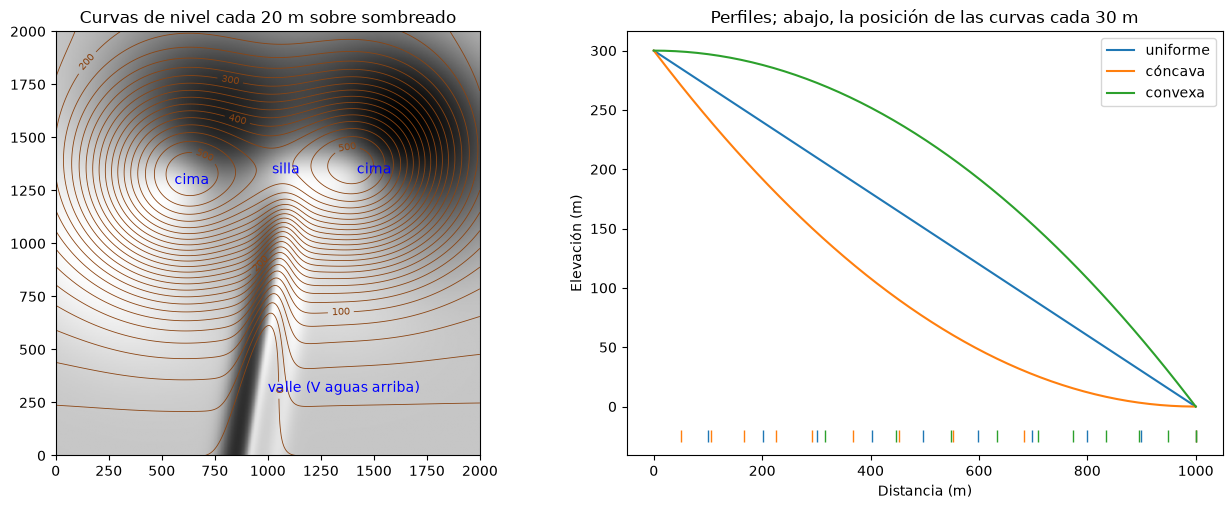

In [2]:
xg, yg = np.meshgrid(np.linspace(0, 2000, 300), np.linspace(0, 2000, 300))
zt = (400 * np.exp(-((xg - 600)**2 + (yg - 1300)**2) / 2.5e5) + 380 * np.exp(-((xg - 1450)**2 + (yg - 1350)**2) / 2.0e5)
      + 0.08 * yg - 90 * np.exp(-((xg - 1000 - 0.15 * (yg - 600))**2) / 8e3) / (1 + np.exp((yg - 1150) / 60)))
from matplotlib.colors import LightSource
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))
ax[0].imshow(LightSource(315, 40).hillshade(zt, dx=6.7, dy=6.7, vert_exag=2), cmap='gray', origin='lower', extent=[0, 2000, 0, 2000])
cs = ax[0].contour(xg, yg, zt, levels=np.arange(0, 600, 20), colors='saddlebrown', linewidths=0.6)
ax[0].clabel(cs, cs.levels[::5], fontsize=7)
ax[0].annotate('silla', (1020, 1330), color='blue'); ax[0].annotate('valle (V aguas arriba)', (1000, 300), color='blue')
ax[0].annotate('cima', (560, 1280), color='blue'); ax[0].annotate('cima', (1420, 1330), color='blue')
ax[0].set_title('Curvas de nivel cada 20 m sobre sombreado')
d = np.linspace(0, 1000, 200)
for nom, z_p in [('uniforme', 300 - 0.3 * d), ('cóncava', 300 * (1 - d / 1000)**2), ('convexa', 300 * (1 - (d / 1000)**2))]:
    ax[1].plot(d, z_p, label=nom)
    for zc in np.arange(0, 300, 30):
        idx = np.argmin(np.abs(z_p - zc)); ax[1].plot(d[idx], -25, '|', color=ax[1].lines[-1].get_color(), ms=8)
ax[1].set_xlabel('Distancia (m)'); ax[1].set_ylabel('Elevación (m)'); ax[1].legend()
ax[1].set_title('Perfiles; abajo, la posición de las curvas cada 30 m')
plt.tight_layout(); plt.show()

## Drenajes y patrones de drenaje

La red de drenaje es el criterio más útil del fotointérprete geólogo, porque los ríos se adaptan a la resistencia y la estructura de las rocas por las que corren {cite}`howard1967`. Se analizan la densidad de drenaje, la forma de los valles y, sobre todo, el patrón. El patrón dendrítico, ramificado como un árbol, es el más común y se forma donde la roca no tiene una estructura que dirija la erosión, como en granitos, gneises masivos, rocas volcánicas o sedimentitas horizontales. El patrón enrejado (trellis), con tributarios cortos que llegan en ángulo recto a corrientes principales paralelas, se forma en secuencias sedimentarias plegadas o inclinadas, donde los ríos siguen los estratos blandos. El rectangular, con quiebres en ángulo recto, refleja sistemas de fracturas o fallas ortogonales. El paralelo se forma en pendientes fuertes y uniformes o sobre geoformas alargadas. El radial, centrífugo, es típico de volcanes y domos, y el anular de domos estructurales erosionados.

La densidad de drenaje, la longitud total de cauces dividida por el área de la cuenca, refleja la permeabilidad y la resistencia de las rocas: es alta en rocas impermeables y blandas, como lutitas o cenizas alteradas, y baja en rocas permeables o muy resistentes, como areniscas, calizas karstificadas o granitos poco fracturados. La celda siguiente genera redes sintéticas con patrones dendrítico, enrejado y rectangular y calcula su densidad y la distribución de las direcciones de sus tramos, que es la forma cuantitativa de reconocer el control estructural.

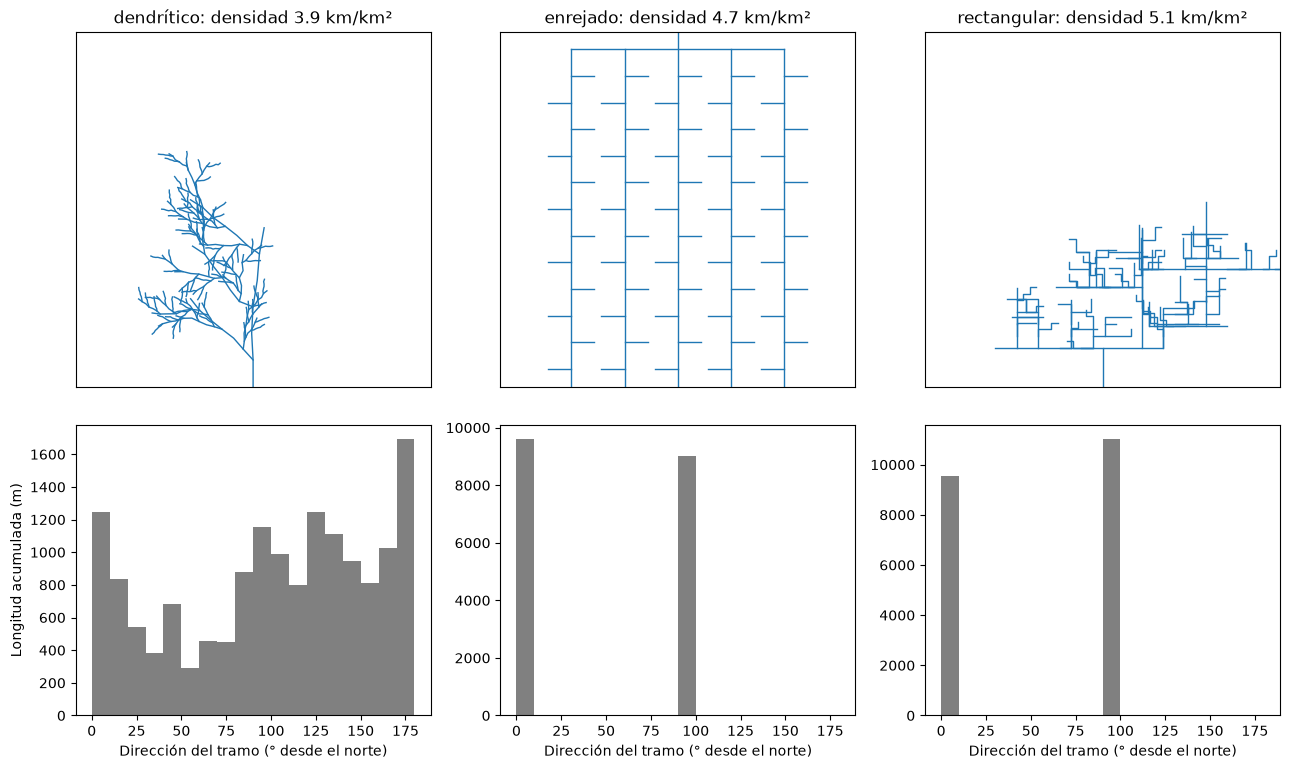

In [3]:
def red_dendritica(rng, x0=0, y0=0, ang=np.pi / 2, largo=900, nivel=0, segs=None):
    segs = [] if segs is None else segs
    if nivel > 4 or largo < 60:
        return segs
    pts = [(x0, y0)]
    for _ in range(6):
        ang_i = ang + rng.normal(0, 0.18)
        x0, y0 = x0 + largo / 6 * np.cos(ang_i), y0 + largo / 6 * np.sin(ang_i)
        pts.append((x0, y0))
    segs.append(np.array(pts))
    for k in range(1, 6, 2):
        lado = 1 if rng.random() < 0.5 else -1
        red_dendritica(rng, *pts[k], ang + lado * rng.uniform(0.5, 0.9), largo * 0.55, nivel + 1, segs)
    return segs

def red_enrejada():
    segs = [np.array([[1000, 0], [1000, 2000]])]
    for xc in [400, 700, 1300, 1600]:
        segs.append(np.array([[xc, 0], [xc, 1900]]))
    for xc in [400, 700, 1000, 1300, 1600]:
        for yc in np.arange(100, 1900, 150):
            segs.append(np.array([[xc, yc], [xc + (130 if (yc // 150) % 2 else -130), yc]]))
    for yc in [1900]:
        segs.append(np.array([[400, yc], [1600, yc]]))
    return segs

def red_rectangular(rng, x0=1000, y0=0, base=np.pi / 2, largo=1100, nivel=0, segs=None):
    """Como la dendrítica, pero cada tramo sigue una de dos familias de fracturas ortogonales (N-S y E-W)."""
    segs = [] if segs is None else segs
    if nivel > 3 or largo < 80:
        return segs
    pts, ang = [(x0, y0)], base
    for _ in range(5):
        if rng.random() < 0.4:
            ang = perpendicular(rng, base) if ang == base else base   # quiebre en ángulo recto
        x0, y0 = x0 + largo / 5 * np.cos(ang), y0 + largo / 5 * np.sin(ang)
        pts.append((x0, y0))
    segs.append(np.array(pts))
    for k in range(1, 5):
        red_rectangular(rng, *pts[k], perpendicular(rng, base), largo * 0.55, nivel + 1, segs)
    return segs

def perpendicular(rng, base):
    """Dirección perpendicular a base que nunca apunta hacia el sur (aguas abajo)."""
    vertical = abs(np.sin(base)) > 0.5
    return rng.choice([0.0, np.pi]) if vertical else np.pi / 2

rng = np.random.default_rng(7)
redes = {'dendrítico': red_dendritica(rng, 1000, 0), 'enrejado': red_enrejada(), 'rectangular': red_rectangular(rng)}
fig, axs = plt.subplots(2, 3, figsize=(13, 8), gridspec_kw={'height_ratios': [3, 2]})
for j, (nom, segs) in enumerate(redes.items()):
    L, angs, pesos = 0, [], []
    for s in segs:
        axs[0, j].plot(s[:, 0], s[:, 1], color='tab:blue', lw=1)
        dxy = np.diff(s, axis=0)
        long_t = np.hypot(dxy[:, 0], dxy[:, 1])
        L += long_t.sum()
        angs += list(np.degrees(np.arctan2(dxy[:, 0], dxy[:, 1])) % 180)
        pesos += list(long_t)
    axs[0, j].set_aspect('equal'); axs[0, j].set_xlim(0, 2000); axs[0, j].set_ylim(0, 2000)
    axs[0, j].set_title(f'{nom}: densidad {L/1000/4:.1f} km/km²')
    axs[0, j].set_xticks([]); axs[0, j].set_yticks([])
    axs[1, j].hist(angs, bins=18, range=(0, 180), weights=pesos, color='0.5')
    axs[1, j].set_xlabel('Dirección del tramo (° desde el norte)')
axs[1, 0].set_ylabel('Longitud acumulada (m)')
plt.tight_layout(); plt.show()

El histograma del patrón dendrítico es amplio, sin direcciones preferentes; los del enrejado y el rectangular tienen picos marcados en dos direcciones perpendiculares, la firma de un control estructural. Con redes de drenaje reales, extraídas de un modelo digital de elevación, el mismo análisis se hace con diagramas de rosas.

## Para profundizar

El capítulo 4 de {cite}`ray1960` y la guía de {cite:t}`gutierrez` presentan los criterios de interpretación con muchos ejemplos de fotos. La clasificación de patrones de drenaje de {cite:t}`howard1967` sigue siendo la referencia básica. El taller de fotointerpretación del curso aplica estos criterios a un par estereoscópico del Valle de Aburrá.